In [ ]:
import pandas as pd
import numpy as np
import os
import xgboost as xgb
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, f1_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
PROCESSED_DIR = r'F:\Abdelrahman1\ME\programming\SIC\Project3.2\data\processed\Forecast'
input_path = os.path.join(PROCESSED_DIR, 'forecast_features_final.csv')

df = pd.read_csv(input_path)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 98146 entries, 0 to 98145
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   timestamp           98146 non-null  object 
 1   actual_power_kw     98146 non-null  float64
 2   ghi                 98146 non-null  float64
 3   tilted_radiation    98146 non-null  float64
 4   temperature         98146 non-null  float64
 5   hour                98146 non-null  int64  
 6   month               98146 non-null  int64  
 7   day_of_week         98146 non-null  int64  
 8   solar_zenith        98146 non-null  float64
 9   solar_elevation     98146 non-null  float64
 10  power_lag_1h        98146 non-null  float64
 11  power_lag_24h       98146 non-null  float64
 12  power_roll_mean_1h  98146 non-null  float64
dtypes: float64(9), int64(3), object(1)
memory usage: 9.7+ MB


In [ ]:
df.head()

,timestamp,actual_power_kw,ghi,tilted_radiation,temperature,hour,month,day_of_week,solar_zenith,solar_elevation,power_lag_1h,power_lag_24h,power_roll_mean_1h
0,2025-01-01 00:00:00,0.0,2.122361,4.169994,25.154861,0,1,2,42.939074,47.060926,0.0,0.0,0.0
1,2025-01-01 00:05:00,0.0,2.309545,4.253466,25.035696,0,1,2,41.808503,48.191497,0.0,0.0,0.0
2,2025-01-01 00:10:00,0.0,2.226635,4.155552,24.824100,0,1,2,40.676999,49.323001,0.0,0.0,0.0
3,2025-01-01 00:15:00,0.0,2.177083,4.063492,24.623623,0,1,2,39.544599,50.455401,0.0,0.0,0.0
4,2025-01-01 00:20:00,0.0,2.419703,4.036308,24.387362,0,1,2,38.411337,51.588663,0.0,0.0,0.0


In [ ]:
df['timestamp'] = pd.to_datetime(df['timestamp'])

In [ ]:
# 1. التقسيم الزمني (Time Series Split)
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx]
test_df = df.iloc[split_idx:]

In [ ]:
target = 'actual_power_kw'
features = [c for c in df.columns if c not in ['timestamp', 'actual_power_kw']]

X_train = train_df[features]
y_train = train_df[target]
X_test = test_df[features]
y_test = test_df[target]

results = []

In [ ]:
# ==========================================
# الموديل الأول: Ridge (Linear Baseline)
# ==========================================
# need scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)
ridge_preds = ridge_model.predict(X_test_scaled)

ridge_mae = mean_absolute_error(y_test, ridge_preds)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_preds))
ridge_r2 = r2_score(y_test, ridge_preds)
# ridge_f1 = f1_score(y_test, ridge_preds)

results.append({
    'Model': 'Ridge (Linear)',
    'MAE': ridge_mae,
    'RMSE': ridge_rmse,
    'R2': ridge_r2,
    # 'F1': ridge_f1
})

In [ ]:
# ==========================================
# الموديل التاني: XGBoost (Tree Ensemble)
# ==========================================
# not need scaling
xgb_model = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42, n_jobs=-1)
xgb_model.fit(X_train, y_train)
xgb_preds = xgb_model.predict(X_test)

xgb_mae = mean_absolute_error(y_test, xgb_preds)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_preds))
xgb_r2 = r2_score(y_test, xgb_preds)
# xgb_f1 = f1_score(y_test, xgb_preds)

results.append({
    'Model': 'XGBoost (Tree)',
    'MAE': xgb_mae,
    'RMSE': xgb_rmse,
    'R2': xgb_r2,
    # 'F1': xgb_f1
})

         Model      MAE     RMSE       R2
XGBoost (Tree) 2.805914 7.274714 0.989771
Ridge (Linear) 4.494220 8.942162 0.984545
XGBoost (Tree) 2.805914 7.274714 0.989771


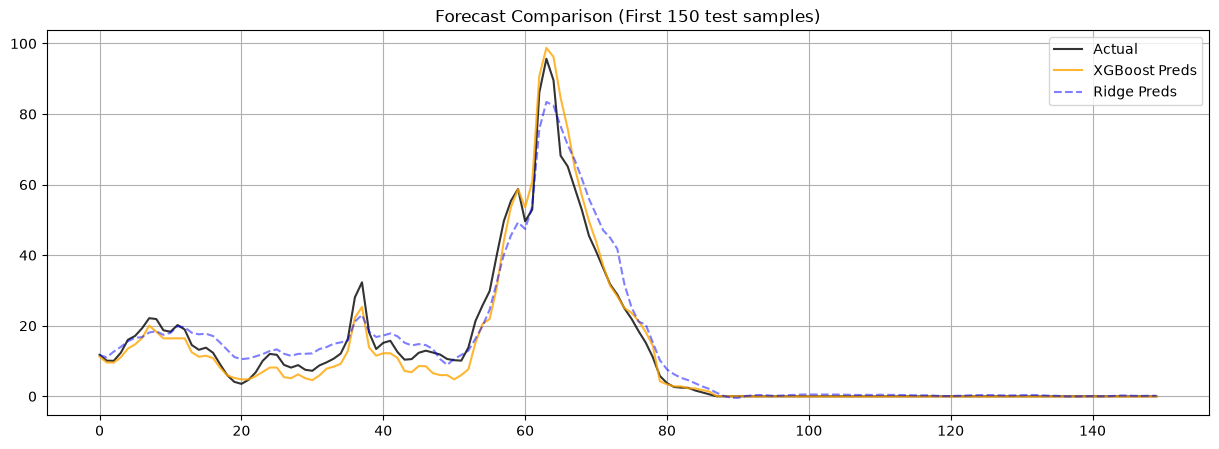

In [ ]:
# ==========================================
# النتائج
# ==========================================
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

# الرسم البياني (بنقارن الـ XGBoost بالأساسي)
plt.figure(figsize=(15, 5))
plt.plot(y_test.values[:150], label='Actual', color='black', alpha=0.8)
plt.plot(xgb_preds[:150], label='XGBoost Preds', color='orange', alpha=0.8)
plt.plot(ridge_preds[:150], label='Ridge Preds', color='blue', alpha=0.5, linestyle='--')
plt.title('Forecast Comparison (First 150 test samples)')
plt.legend()
plt.grid(True)
plt.show()